In [1]:
import numpy as np
from scipy.linalg import cholesky, solve_triangular, svd
import matplotlib.pyplot as plt
import time
import pandas as pd

from sklearn.preprocessing import StandardScaler
from KRR_utils import *
from nystrom_functions import *

In [2]:
rng = np.random.default_rng(1)

df = pd.read_csv("../Data/train.csv")
X = df.iloc[:, :-1].to_numpy(dtype=float)
y = df.iloc[:, -1].to_numpy(dtype=float)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

n = 20000
ind = rng.choice(X_scaled.shape[0], size=n, replace=False)
X_now = X_scaled[ind]
y_now = y[ind]

gamma = 1/X_now.shape[1]

def rbf3(A, B):
    K = rbf(A, B, gamma=gamma)
    return K

K = make_kernel_matrix(X_now, rbf3)


kernel = linear
full krr mse = 1550.8609763643606
full krr runtime = 0.6014750999747775

l = 1
uniform mse = 52662596072379.02
uniform forward error = 0.6206551334266399
uniform runtime = 0.6989089000271633
gaussian mse = 332993376401026.75
gaussian forward error = 0.8401582189152312
gaussian runtime = 0.6973036000272259

l = 21
uniform mse = 79094911696.61778
uniform forward error = 0.08434012606187162
uniform runtime = 0.5440655000275001
gaussian mse = 170201324505.90558
gaussian forward error = 0.07015630105950599
gaussian runtime = 0.8466699999989942

l = 41
uniform mse = 748914924.9560753
uniform forward error = 0.015037437137094807
uniform runtime = 0.5779137999634258
gaussian mse = 275634425.48727983
gaussian forward error = 0.011803914354955897
gaussian runtime = 0.6514443000196479

l = 61
uniform mse = 9428800.336812114
uniform forward error = 0.002248035816112976
uniform runtime = 0.7053886999492534
gaussian mse = 11945711.461482983
gaussian forward error = 0.001721746685122

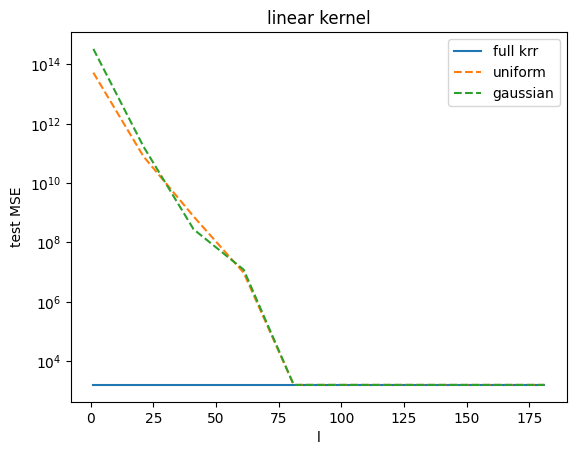

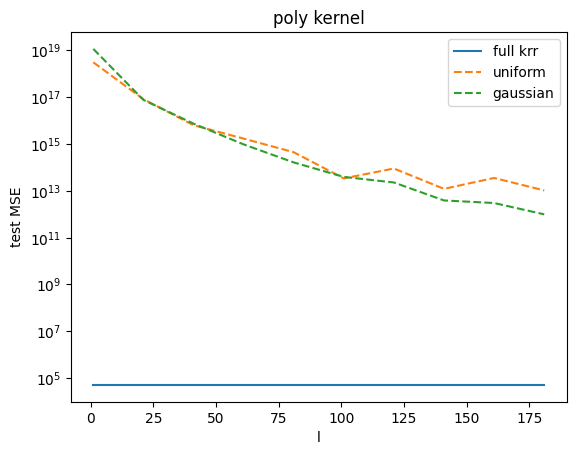

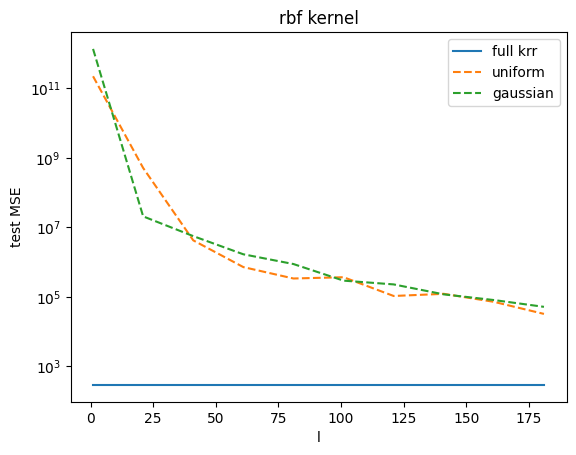

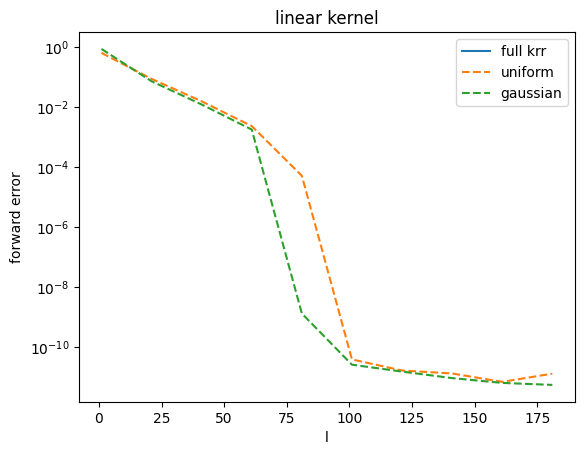

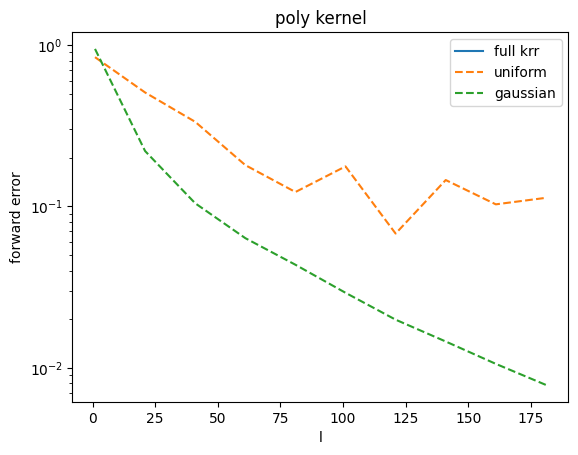

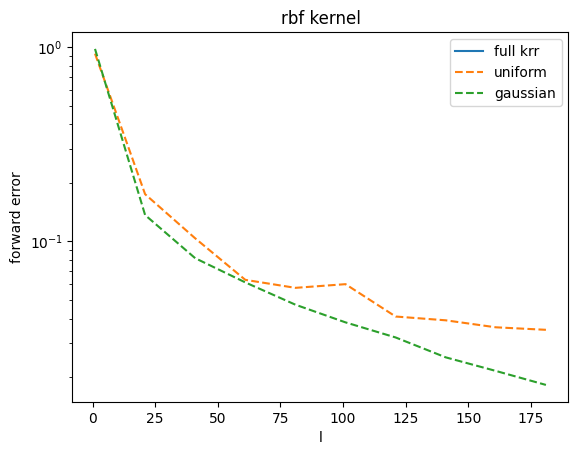

In [ ]:
# real data version of the old fake data experiment

rng = np.random.default_rng(1)

df = pd.read_csv("../Data/train.csv")
X = df.iloc[:, :-1].to_numpy(dtype=float)
y = df.iloc[:, -1].to_numpy(dtype=float)

n_train = 800
n_test = 300
lam = 1e-2

ind = rng.choice(X.shape[0], size=n_train + n_test, replace=False)

train_ind = ind[:n_train]
test_ind = ind[n_train:]
X_train_raw = X[train_ind]
y_train = y[train_ind]
X_test_raw = X[test_ind]
y_test = y[test_ind]
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

gamma = 1/X_train.shape[1]

def rbf5(A, B):
    K = rbf(A, B, gamma=gamma)
    return K

def get_error(y_test, y_hat): #mse
    err = np.mean((y_test-y_hat)**2)
    return err

kernel_names = ["linear", "poly", "rbf"]
kernel_list = [linear, poly, rbf5]
l_values = range(1, 200, 20)
results = []

for a in range(len(kernel_list)):
    name = kernel_names[a]
    kernel = kernel_list[a]
    print("")
    print("kernel =", name)

    t0 = time.perf_counter()

    K_train = kernel(X_train, X_train)
    K_test = kernel(X_test, X_train)
    alpha = np.linalg.solve(K_train + lam*np.eye(n_train), y_train) #full krr
    y_hat = K_test @ alpha
    full_time = time.perf_counter() - t0
    full_mse = get_error(y_test, y_hat)

    print("full krr mse =", full_mse)
    print("full krr runtime =", full_time)

    for l in l_values:
        print("")
        print("l =", l)

        t0 = time.perf_counter()

        sample_ind = rng.choice(n_train, size=l, replace=False) #random uniform
        C = K_train[:, sample_ind]
        W = K_train[sample_ind, :]
        W = W[:, sample_ind]
        K_uni = C @ np.linalg.pinv(W) @ C.T
        alpha_uni = np.linalg.solve(K_uni + lam*np.eye(n_train), y_train)
        y_hat_uni = K_test @ alpha_uni

        uni_time = time.perf_counter() - t0

        uni_mse = get_error(y_test, y_hat_uni)
        uni_fro = np.linalg.norm(K_train-K_uni, ord="fro")/np.linalg.norm(K_train, ord="fro")

        print("uniform mse =", uni_mse)
        print("uniform forward error =", uni_fro)
        print("uniform runtime =", uni_time)

        t0 = time.perf_counter()

        U, eigs, K_gauss = random_nystrom(K_train, l, l, rng) #gaussian method
        alpha_gauss = np.linalg.solve(K_gauss + lam*np.eye(n_train), y_train)
        y_hat_gauss = K_test @ alpha_gauss

        gauss_time = time.perf_counter() - t0

        gauss_mse = get_error(y_test, y_hat_gauss)
        gauss_fro = np.linalg.norm(K_train-K_gauss, ord="fro")/np.linalg.norm(K_train, ord="fro")

        print("gaussian mse =", gauss_mse)
        print("gaussian forward error =", gauss_fro)
        print("gaussian runtime =", gauss_time)

        results.append([name, l, "full", full_mse, 0.0, full_time])
        results.append([name, l, "uniform", uni_mse, uni_fro, uni_time])
        results.append([name, l, "gaussian", gauss_mse, gauss_fro, gauss_time])

print("")
print("results")
print("kernel, l, method, mse, forward error, time")
for row in results:
    print(row)

for name in kernel_names:
    l_plot = []
    full_plot = []
    uni_plot = []
    gauss_plot = []

    for row in results:
        if row[0] == name and row[2] == "full":
            l_plot.append(row[1])
            full_plot.append(row[3])
        if row[0] == name and row[2] == "uniform":
            #l_plot.append(row[1])
            uni_plot.append(row[3])
        if row[0] == name and row[2] == "gaussian":
            gauss_plot.append(row[3])

    plt.figure()
    plt.semilogy(l_plot,full_plot,label="full krr")
    plt.semilogy(l_plot,uni_plot,'--',label="uniform")
    plt.semilogy(l_plot,gauss_plot,'--',label="gaussian")
    plt.xlabel("l")
    plt.ylabel("test MSE")
    plt.title(name + " kernel")
    plt.legend()
    #plt.savefig("../Results/" + name + "_kernel_test_mse_vs_l.pdf")
    plt.show()

for name in kernel_names:

    l_plot = []
    full_plot = []
    uni_plot = []
    gauss_plot = []

    for row in results:
        if row[0] == name and row[2] == "full":
            l_plot.append(row[1])
            full_plot.append(row[4])
        if row[0] == name and row[2] == "uniform":
            #l_plot.append(row[1])
            uni_plot.append(row[4])
        if row[0] == name and row[2] == "gaussian":
            gauss_plot.append(row[4])

    plt.figure()
    plt.semilogy(l_plot,full_plot, label="full krr")
    plt.semilogy(l_plot,uni_plot, '--', label="uniform")
    plt.semilogy(l_plot,gauss_plot,'--',label="gaussian")
    plt.xlabel("l")
    plt.ylabel("forward error")
    plt.title(name + " kernel")
    plt.legend()
    #plt.savefig("../Results/" + name + "_kernel_forward_error_vs_l.pdf")
    plt.show()

Okay, next we look at ...


l = 50
uniform forward error = 0.09107724136349782
gaussian forward error = 0.07306810610147282

l = 100
uniform forward error = 0.0512281814409809
gaussian forward error = 0.04332519541132793

l = 200
uniform forward error = 0.03258808031599075
gaussian forward error = 0.02146883070891649

l = 400
uniform forward error = 0.01875832344014881
gaussian forward error = 0.009745988248997781

l = 800
uniform forward error = 0.010598519978526195
gaussian forward error = 0.003685768495021435


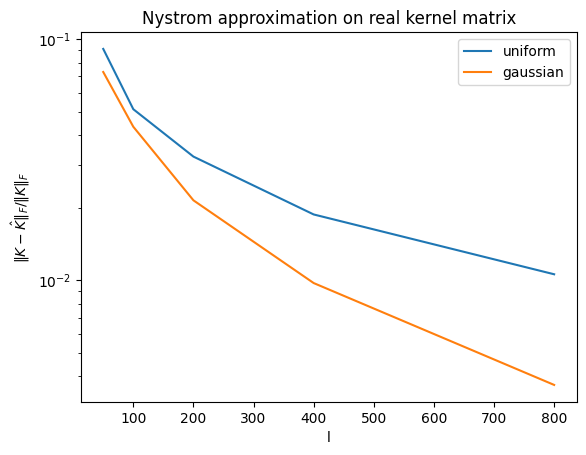

In [ ]:
# Uniform column sampling vs randomized Nystrom on real data

l_values = [50, 100, 200, 400, 800]
l_plot = []
uni_plot = []
gauss_plot = []

for l in l_values:

    sample_ind = rng.choice(n, size=l, replace=False)
    K_uni = nystrom_CWCT(K, sample_ind)

    U, lam_gauss, K_gauss = random_nystrom(K, l, l, rng)

    uni_err = np.linalg.norm(K - K_uni, ord="fro") / np.linalg.norm(K, ord="fro")
    gauss_err = np.linalg.norm(K - K_gauss, ord="fro") / np.linalg.norm(K, ord="fro")

    print("")
    print("l =", l)
    print("uniform forward error =", uni_err)
    print("gaussian forward error =", gauss_err)

    l_plot.append(l)
    uni_plot.append(uni_err)
    gauss_plot.append(gauss_err)

plt.figure()
plt.semilogy(l_plot, uni_plot, label="uniform")
plt.semilogy(l_plot, gauss_plot, label="gaussian")
plt.xlabel("l")
plt.ylabel("$\|K-\hat K\|_F/\|K\|_F$")
plt.title("Nystrom approximation on real kernel matrix")
plt.legend()
#plt.savefig("../Results/uniform_gaussian_forward_error_real_kernel.pdf")
plt.show()

In [5]:
# exact and approximate leverage score comparison

score_n = 300
r = 50
ini_l = 100
score_ind = rng.choice(K.shape[0], size=score_n, replace=False)
K_score = K[np.ix_(score_ind, score_ind)]
val, vec = np.linalg.eigh(K_score)
U_exact = vec[:, -r:]
exact_scores = np.sum(U_exact**2, axis=1)
ini_ind = uniform_sampling(score_n, ini_l, rng)
K1 = K_score[:, ini_ind]
U_app, sigma_app, VT_app = np.linalg.svd(K1, full_matrices=False)
U_app = U_app[:, :r]
approx_scores = np.sum(U_app**2, axis=1)
order = np.argsort(exact_scores)[::-1]
exact_sorted = exact_scores[order]
approx_sorted = approx_scores[order]

score_df = pd.DataFrame({
    "column": np.arange(score_n),
    "exact_score": exact_sorted,
    "approx_score": approx_sorted
})

score_df.to_csv("../Results/exact_vs_approx_leverage_scores.csv", index=False)
score_df

,column,exact_score,approx_score
0,0,0.999721,0.000098
1,1,0.945776,0.004275
2,2,0.846351,0.048716
3,3,0.845758,0.054767
4,4,0.737674,0.056331
...,...,...,...
295,295,0.022069,0.025611
296,296,0.021726,0.031804
297,297,0.018726,0.022347
298,298,0.017183,0.018770


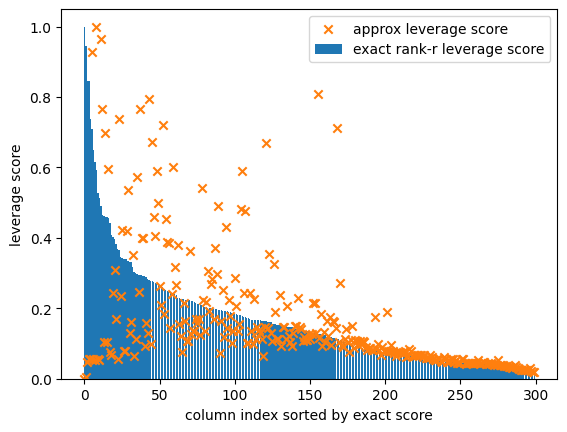

In [ ]:
plt.figure()
plt.bar(score_df["column"], score_df["exact_score"], label="exact rank-r leverage score")
plt.scatter(score_df["column"], score_df["approx_score"], marker="x", label="approx leverage score")
plt.xlabel("column index sorted by exact score")
plt.ylabel("leverage score")
plt.legend()
#plt.savefig("../Results/exact_vs_approx_leverage_scores.pdf") 
plt.show()

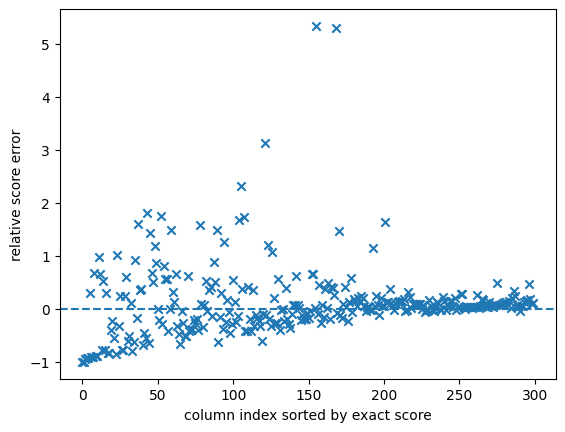

In [ ]:
relative_score_error = (approx_sorted - exact_sorted) / (exact_sorted + 1e-10) #avoid division by zero

plt.figure()
plt.scatter(np.arange(score_n), relative_score_error, marker="x")
plt.axhline(0, linestyle="--")
plt.xlabel("column index sorted by exact score")
plt.ylabel("relative score error")
#plt.savefig("../Results/relative_leverage_score_error.pdf") 
plt.show()

In [ ]:
# effect of initial uniform sample size on approximate score error and runtime

ini_l_values = [50, 80, 100, 150, 200, 300]
score_rows = []

# exact rank-r score time on the same 300 x 300 matrix
start_time = time.perf_counter()

val, vec = np.linalg.eigh(K_score)
U_exact = vec[:, -r:]
exact_scores = np.sum(U_exact**2, axis=1)

exact_score_time = time.perf_counter() - start_time

for ini_l in ini_l_values:

    start_time = time.perf_counter()

    ini_ind = uniform_sampling(score_n, ini_l, rng)
    K1 = K_score[:, ini_ind]
    U_app, sigma_app, VT_app = np.linalg.svd(K1, full_matrices=False)
    U_app = U_app[:, :r]
    approx_scores = np.sum(U_app**2, axis=1)

    approx_score_time = time.perf_counter() - start_time
    
    relative_error = (approx_scores - exact_scores) / (exact_scores + 1e-10)
    mean_abs_relative_error = np.mean(np.abs(relative_error))
    max_abs_relative_error = np.max(np.abs(relative_error))
    
    score_rows.append([ini_l, mean_abs_relative_error, max_abs_relative_error, approx_score_time])

score_error_df = pd.DataFrame(score_rows, columns=["initial_l", "mean_abs_relative_error", "max_abs_relative_error", "score_time"])

score_error_df.to_csv("../Results/approx_score_error_vs_initial_l.csv", index=False)
score_error_df

,initial_l,mean_abs_relative_error,max_abs_relative_error,score_time
0,50,6.076703e-01,4.648709e+00,0.002647
1,80,4.478428e-01,3.354138e+00,0.005219
2,100,3.731742e-01,3.097278e+00,0.009325
3,150,2.433795e-01,2.345010e+00,0.015896
4,200,1.492154e-01,1.096951e+00,0.016585
5,300,2.967661e-15,1.808989e-14,0.033275


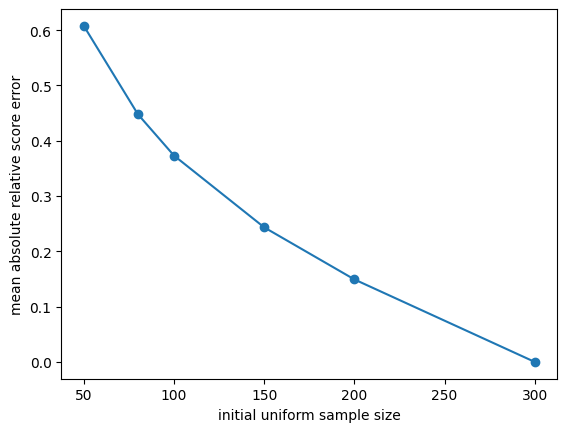

In [ ]:
plt.figure()
plt.plot(score_error_df["initial_l"], score_error_df["mean_abs_relative_error"], marker="o")
plt.xlabel("initial uniform sample size")
plt.ylabel("mean absolute relative score error")
#plt.savefig("../Results/score_error_vs_initial_l.pdf") 
plt.show()

In [11]:
# Nystrom error with fixed total sample size and varying initial uniform sample size

small_n = 2000
small_n_ind = rng.choice(K.shape[0], size=small_n, replace=False)
K_small = K[np.ix_(small_n_ind, small_n_ind)]

r = 50
final_l = 300
ini_ls = [50, 80, 100, 150, 200]
cycles = 5
K_norm = np.linalg.norm(K_small, ord="fro")

full_errors = []

for cycle in range(cycles):
    full_ind, full_scores = full_leverage(K_small, r, final_l, rng)
    K_full = nystrom_CWCT(K_small, full_ind)
    err_full = np.linalg.norm(K_small - K_full, ord="fro") / K_norm
    full_errors.append(err_full)

err_full = np.mean(full_errors)

app_errors = []

for ini_l in ini_ls:

    extra_l = final_l - ini_l
    errors = []

    for cycle in range(cycles):
        app_ind, app_scores, ini_ind = approximate_leverage(K_small, ini_l, extra_l, rng)
        K_app = nystrom_CWCT(K_small, app_ind)
        err_app = np.linalg.norm(K_small - K_app, ord="fro") / K_norm
        errors.append(err_app)

    app_errors.append(np.mean(errors))

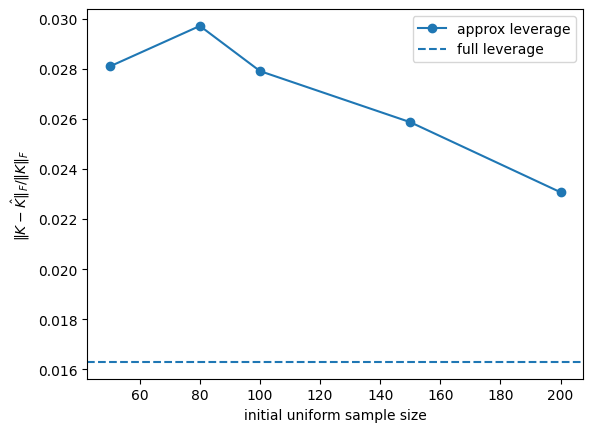

In [ ]:
plt.figure()
plt.plot(ini_l_values, app_errors, marker="o", label="approx leverage")
plt.axhline(err_full, linestyle="--", label="full leverage")
plt.xlabel("initial uniform sample size")
plt.ylabel("$\|K-\hat K\|_F/\|K\|_F$")
plt.legend()
#plt.savefig("../Results/nystrom_error_vs_initial_l.pdf") 
plt.show()

In [5]:
plt.figure()
timing_df = score_error_df[score_error_df["initial_l"] < 300]
plt.plot( timing_df["initial_l"], timing_df["score_time"], marker="o", label="approx leverage")
plt.axhline( exact_score_time, linestyle="--", label="exact leverage")
plt.xlabel("initial uniform sample size")
plt.ylabel("runtime(s)")
plt.legend()
#plt.savefig( "../Results/sampling_time_vs_initial_l.pdf")
plt.show()

NameError: name 'score_error_df' is not defined

<Figure size 640x480 with 0 Axes>